# MR-KLT on real MeerKAT data

Applies the **Multiple-Realisation KLT (MR-KLT)** to real MeerKAT /
Breakthrough Listen `.stamps` files (BLUSE backend, read with `seticore`).
Each stamp has shape `(T, F, P, A)` = (timesteps, channels, polarisations,
antennas); for a single channel/polarisation the antenna vector at each
timestep gives an `(K, N_A) = (T, A)` matrix that feeds `apply_mrklt`.

The notebook: loads a stamp, locates the strongest channel, runs MR-KLT
per channel, estimates the signal count with the Kritchman-Nadler rank
estimator (`KN_rankEst`), and visualises the dominant eigenvector,
the per-channel rank/coherence, and the waterfall / PSD / eigenspectrum.

> **Status:** work in progress. Requires `seticore` and MeerKAT stamp data
> under `data/stamps_data/` (git-ignored).


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from seti_klt import KLT, scan_channels
from seti_klt.utils.io import (
    SimpleLogger,
    LogLevel,
    prepare_output_dir,
    save_figure,
)

np.random.seed(0)
plt.rcParams["figure.dpi"] = 110

# Logger: console + outputs/logs/mrklt_meerkat.log
logger = SimpleLogger(level=LogLevel.INFO, filename="mrklt_meerkat.log")
logger.section("MR-KLT MeerKAT Pipeline Initialization")

# Figures are written to outputs/figures via save_figure()
prepare_output_dir("outputs/figures")

# Analysis parameters
POL      = 0        # polarization 0 (switch to 1 for comparison)
KN_ALPHA = 0.01     # Kritchman-Nadler false-alarm rate (percentage points)

/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/blimpy/__init__.py:21: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Logging to: /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/logs/mrklt_meerkat.log

=== MR-KLT MEERKAT PIPELINE INITIALIZATION


In [2]:
from seticore import viewer
from seti_klt.utils import get_data_path, get_random_file_path

DATA_PATH = get_data_path() / "stamps_data"
# STAMPS_PATH = DATA_PATH / "stamps_data/blpn64/buf0/data/20250705T194745Z-20250703-0012/seticore_search/guppi_60861_71265_001656_J1955+1154T2_0001.stamps"
STAMPS_PATH = get_random_file_path(target_directory=DATA_PATH, random_seed=42)

stamps_gen = viewer.read_stamps(STAMPS_PATH, find_recipe=False)
stamps = []
for stamp in stamps_gen:
    assert stamp is not None
    stamps.append(stamp)

print(f"File: {STAMPS_PATH}")
print(f"# Stamps in the file: {len(stamps)}")

kj/filesystem-disk-unix.c++:1734: warning: PWD environment variable doesn't match current directory; pwd = /mnt/c/Users/gigig/AppData/Local/Programs/Microsoft VS Code


File: /mnt/c/Users/gigig/Documents/University/SETI/codes/data/stamps_data/blpn64/buf0/data/20250727T145333Z-20250723-0028/seticore_search/guppi_60883_53613_001461_J1726-5529_0001.stamps
# Stamps in the file: 3


In [3]:
import pprint

STAMP_IDX = 1
stamp = stamps[STAMP_IDX]

stamp_obj = stamp.stamp

metadata = {
    field: getattr(stamp_obj, field) 
    for field in stamp_obj.schema.fields 
    if field != 'data'
}

metadata_of_interest = ['obsid', 'sourceName', 'ra', 'dec', 'signal']
metadata_to_print = {k: metadata[k] for k in metadata_of_interest if k in metadata}

print("=== METADATA ===")
pprint.pprint(metadata_to_print)
print("\n")

data  = stamp.complex_array()

T, F, P, A = data.shape
print(f"Stamp {STAMP_IDX}:")
print(f"  # Timesteps:    {T}   <- K (realizations for MR-KLT)")
print(f"  # Channels:     {F}   <- Frequency")
print(f"  # Polarization: {P}   <- (LCP/RCP)")
print(f"  # Antennas:     {A}   <- W (Covariance matrix dimension)")
print(f"\ngamma = N_A/(K-1) = {A}/{T-1} = {A/(T-1):.4f}")
print(f"\ndtype: {data.dtype}")
print(f"Average Power (|x|²): {np.mean(np.abs(data)**2):.4f}")

=== METADATA ===
{'dec': -55.49458333333333,
 'obsid': 'MeerKAT:array_1:20250727T145333Z',
 'ra': 17.447119444444446,
 'signal': <hit.capnp:Signal reader (frequency = 1976.0118422564119, index = 64713, driftSteps = 24, driftRate = 0.25706083766995025, snr = 9.3821383, coarseChannel = 34, beam = 0, numTimesteps = 24, power = 1.2210259e16, incoherentPower = 9.67779e15)>,
 'sourceName': 'J1726-5529'}


Stamp 1:
  # Timesteps:    197   <- K (realizations for MR-KLT)
  # Channels:     85   <- Frequency
  # Polarization: 2   <- (LCP/RCP)
  # Antennas:     60   <- W (Covariance matrix dimension)

gamma = N_A/(K-1) = 60/196 = 0.3061

dtype: complex128
Average Power (|x|²): 7612164.9901


Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_power_per_channel.png
[15:38:17] [INFO]     Channel with the highest power: 33


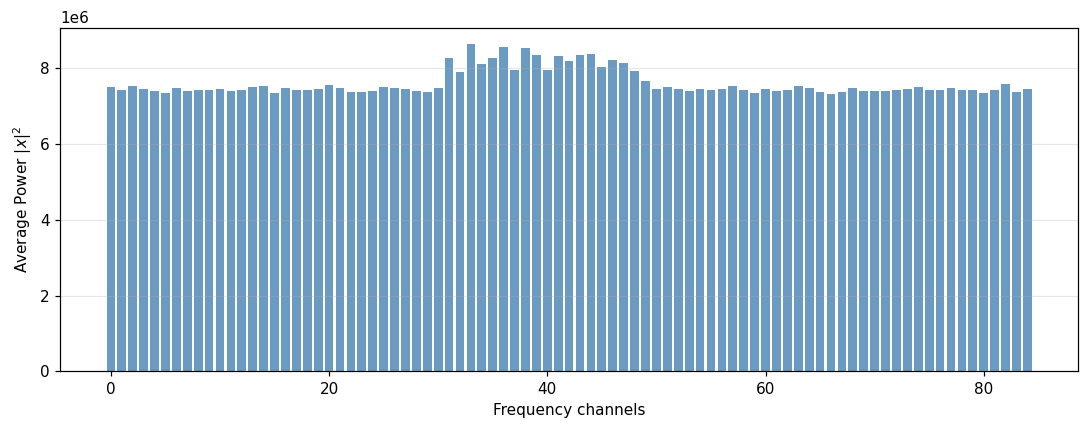

In [4]:
%matplotlib inline

power_per_channel = np.mean(np.abs(data)**2, axis=(0, 2, 3))  # average over T, P, A

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(F), power_per_channel, color="steelblue", alpha=0.8)
ax.set_xlabel("Frequency channels")
ax.set_ylabel("Average Power $|x|^2$")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
save_figure(fig, filename=f"stamp{STAMP_IDX}_power_per_channel.png")

dominant_ch = int(np.argmax(power_per_channel))
logger.info(f"Channel with the highest power: {dominant_ch}")

In [5]:
FREQ_CH = dominant_ch    # strongest-signal channel

x = data[:, FREQ_CH, POL, :]   # shape (K, N_A)
logger.info(f"Input MR-KLT: shape={x.shape}  (K={T}, N_A={A})")

klt = KLT(logger=logger)
klt.load_signal_from_array(x)
klt.apply_mrklt(n_eigenvectors=1)

[15:38:22] [INFO]     Input MR-KLT: shape=(197, 60)  (K=197, N_A=60)
[15:38:22] [INFO]     Signal loaded from array — shape: (197, 60), dtype: complex128.

=== APPLYING MR-KLT
[15:38:22] [INFO]     Realisations (K): 197 | Antennas (N_A): 60 | gamma: 0.3061 | eigenvectors to keep: 1.
[15:38:22] [INFO]     Top eigenvalue: 59359924.4386 | 2nd eigenvalue: 20620348.4354 | gap ratio λ₁/λ₂: 2.88x.
[15:38:22] [INFO]     Reconstruction complete — output shape: (197, 60) (K timesteps × N_A antennas).


Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_ch33_eigenvector.png


PosixPath('/mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_ch33_eigenvector.png')

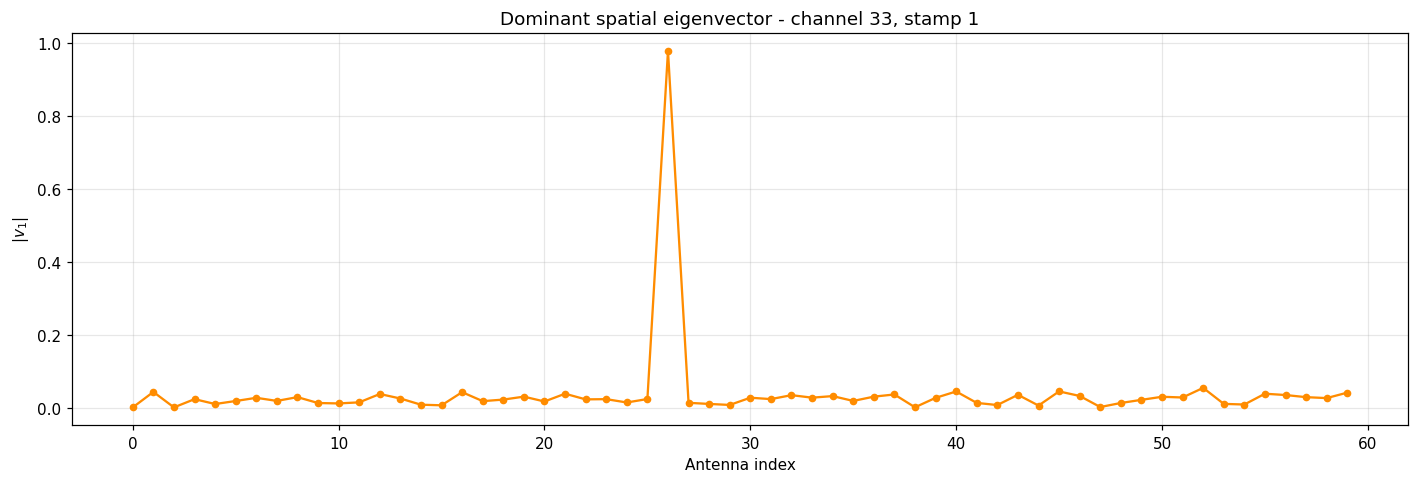

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.5))

v1 = klt.get_eigenvectors()[:, 0]
ax.plot(np.abs(v1), "o-", color="darkorange", markersize=4, lw=1.5)
ax.set_xlabel("Antenna index")
ax.set_ylabel(r"$|v_1|$")
ax.set_title(f"Dominant spatial eigenvector - channel {FREQ_CH}, stamp {STAMP_IDX}")
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, filename=f"stamp{STAMP_IDX}_ch{FREQ_CH}_eigenvector.png")

In [7]:
stamp.show_antennas()

/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/seticore/viewer.py:349: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([
/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/seticore/viewer.py:358: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/seticore/viewer.py:358: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([
/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/seticore/viewer.py:358: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or u


=== PER-CHANNEL MR-KLT SWEEP
[15:38:44] [INFO]     Reference channel (strongest lambda1): 33
[15:38:44] [INFO]     Channels with a detected signal: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_rank_and_coherence.png


PosixPath('/mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_rank_and_coherence.png')

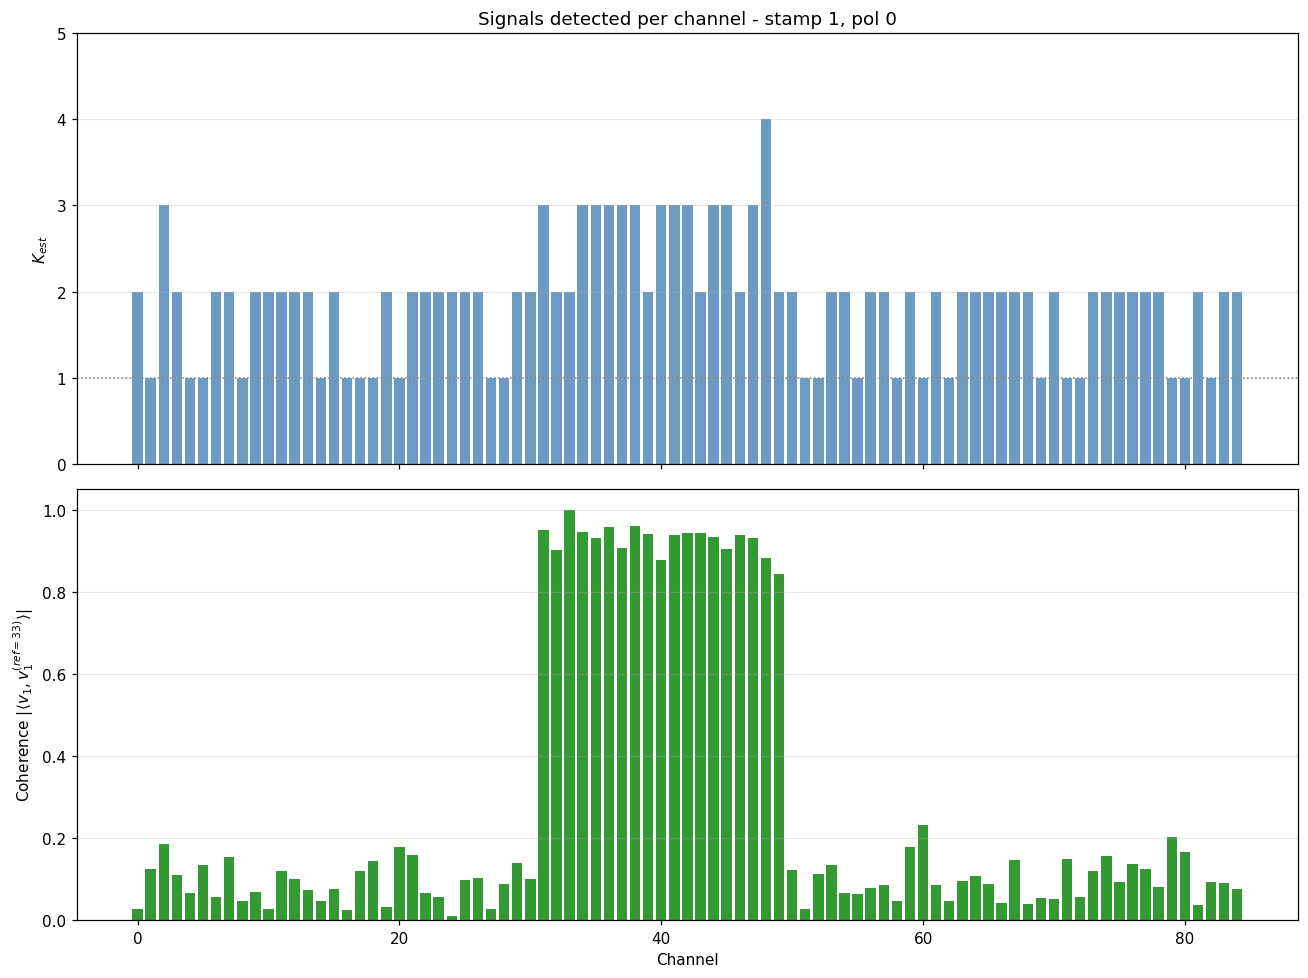

In [8]:
logger.section("Per-Channel MR-KLT Sweep")

# A single sweep for the whole notebook: per frequency channel it runs the MR-KLT,
# estimates the number of signals with Kritchman-Nadler, and reconstructs the
# signal subspace. Same function used by the simulated pipeline in ../MAA_Simulated/.
scan = scan_channels(
    data[:, :, POL, :],      # (T, F, P, A) -> (K, F, N_A)
    alpha=KN_ALPHA,
    beta=2,                  # complex (I/Q) baseband
)

ref_ch     = int(np.nanargmax(scan.lambda1))
coherences = scan.eigenvector_coherence(ref_channel=ref_ch)

logger.info(f"Reference channel (strongest lambda1): {ref_ch}")
logger.info(f"Channels with a detected signal: {scan.detected_channels()}")

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

axes[0].bar(range(F), scan.k_est, color="steelblue", alpha=0.8)
axes[0].axhline(1, color="gray", ls=":", lw=1)
axes[0].set_ylabel("$K_{est}$")
axes[0].set_yticks(range(0, int(scan.k_est.max()) + 2))
axes[0].set_title(f"Signals detected per channel - stamp {STAMP_IDX}, pol {POL}")
axes[0].grid(alpha=0.3, axis="y")

axes[1].bar(range(F), coherences, color="green", alpha=0.8)
axes[1].set_xlabel("Channel")
axes[1].set_ylabel(f"Coherence $|\\langle v_1, v_1^{{(ref={ref_ch})}} \\rangle|$")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
save_figure(fig, filename=f"stamp{STAMP_IDX}_rank_and_coherence.png")


=== WATERFALL, PSD AND EIGENSPECTRUM
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_waterfall.png
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_psd_comparison.png
Figure saved → /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/figures/stamp1_ch33_eigenspectrum.png
[15:38:48] [INFO]     Pipeline executed successfully. All assets saved locally.
Log closed: /mnt/c/Users/gigig/Documents/University/SETI/codes/notebooks/Meerkat_Real_Data/outputs/logs/mrklt_meerkat.log


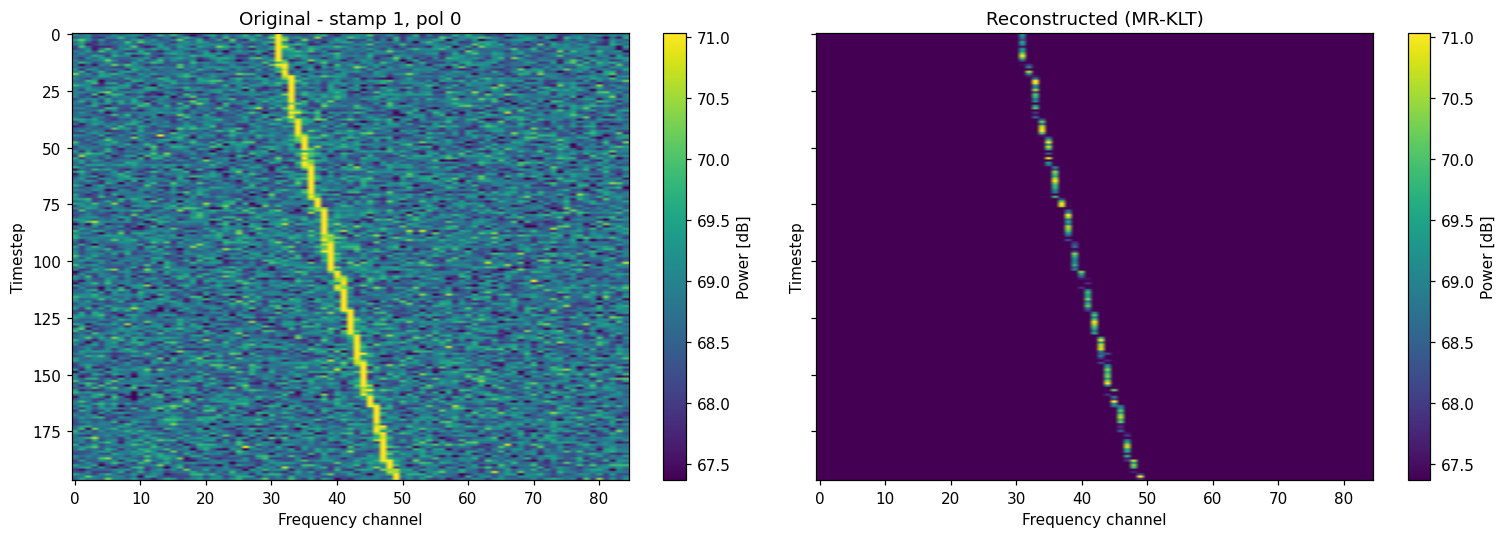

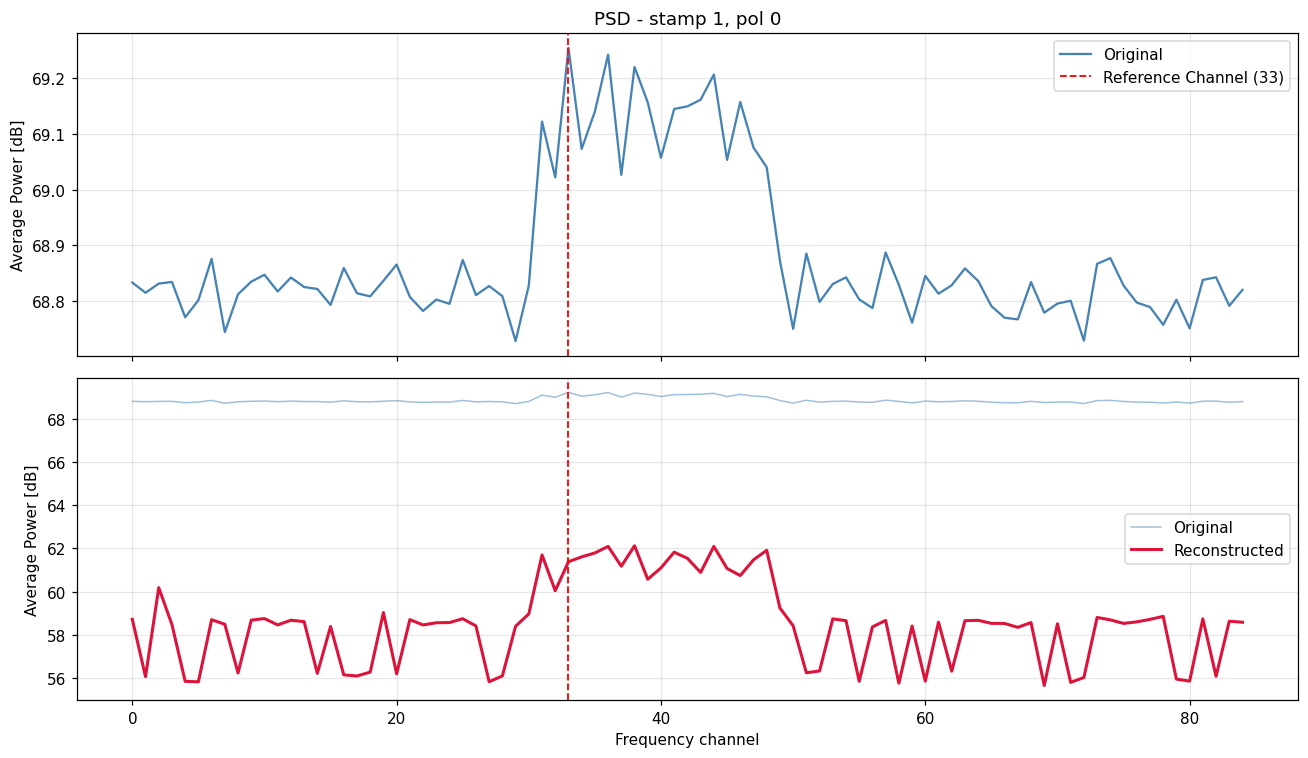

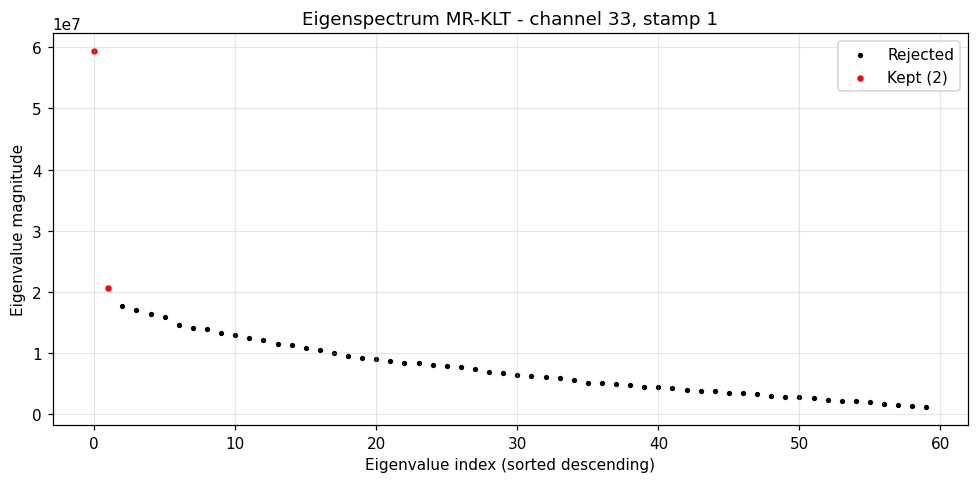

In [9]:
logger.section("Waterfall, PSD and Eigenspectrum")

power_orig  = scan.power_orig     # (K, F)
power_recon = scan.power_recon    # (K, F)

# --- WATERFALL ---
vmin = float(np.nanpercentile(10*np.log10(power_orig + 1e-30), 1))
vmax = float(np.nanpercentile(10*np.log10(power_orig + 1e-30), 99))

fig_wf, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, power, title in [
    (axes[0], power_orig,  f"Original - stamp {STAMP_IDX}, pol {POL}"),
    (axes[1], power_recon, "Reconstructed (MR-KLT)"),
]:
    im = ax.imshow(
        10*np.log10(power + 1e-30),
        aspect="auto", cmap="viridis", origin="upper",
        vmin=vmin, vmax=vmax,
        extent=[-0.5, F-0.5, T-0.5, -0.5],
    )
    ax.set_xlabel("Frequency channel")
    ax.set_ylabel("Timestep")
    ax.set_title(title)
    fig_wf.colorbar(im, ax=ax, label="Power [dB]")
fig_wf.tight_layout()
save_figure(fig_wf, filename=f"stamp{STAMP_IDX}_waterfall.png")

# --- PSD ---
psd_orig  = np.nanmean(power_orig,  axis=0)
psd_recon = np.nanmean(power_recon, axis=0)

fig_psd, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(range(F), 10*np.log10(psd_orig + 1e-30),
             color="steelblue", lw=1.5, label="Original")
axes[0].axvline(FREQ_CH, color="red", ls="--", lw=1.2,
                label=f"Reference Channel ({FREQ_CH})")
axes[0].set_ylabel("Average Power [dB]")
axes[0].set_title(f"PSD - stamp {STAMP_IDX}, pol {POL}")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(range(F), 10*np.log10(psd_orig + 1e-30),
             color="steelblue", lw=1, alpha=0.5, label="Original")
axes[1].plot(range(F), 10*np.log10(psd_recon + 1e-30),
             color="crimson",   lw=2,            label="Reconstructed")
axes[1].axvline(FREQ_CH, color="red", ls="--", lw=1.2)
axes[1].set_xlabel("Frequency channel")
axes[1].set_ylabel("Average Power [dB]")
axes[1].legend(); axes[1].grid(alpha=0.3)
fig_psd.tight_layout()
save_figure(fig_psd, filename=f"stamp{STAMP_IDX}_psd_comparison.png")

# --- EIGENSPECTRUM ---
evals  = scan.eigenvalues[FREQ_CH]
n_kept = int(scan.k_est[FREQ_CH])

fig_spec, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(range(n_kept, len(evals)), evals[n_kept:],
           color="black", s=6,  label="Rejected")
ax.scatter(range(n_kept), evals[:n_kept],
           color="red",   s=10, label=f"Kept ({n_kept})")
ax.set_xlabel("Eigenvalue index (sorted descending)")
ax.set_ylabel("Eigenvalue magnitude")
ax.set_title(f"Eigenspectrum MR-KLT - channel {FREQ_CH}, stamp {STAMP_IDX}")
ax.legend(); ax.grid(alpha=0.3)
fig_spec.tight_layout()
save_figure(fig_spec, filename=f"stamp{STAMP_IDX}_ch{FREQ_CH}_eigenspectrum.png")

logger.info("Pipeline executed successfully. All assets saved locally.")
logger.close()